<a href="https://colab.research.google.com/github/thisaraniNJ/Individual_Research_Project/blob/dev/UniFoil_Preprocessing_Visualisation_Standalone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UniFoil preprocessing and visualisation notebook

**Purpose:** run the preprocessing pipeline embedded in this notebook on the downloaded UniFoil raw files, inspect the prepared outputs, and create diagnostic visualisations.

This notebook is an analysis/visualisation wrapper around the uploaded script. It does **not** rewrite its preprocessing algorithms. It reads the same output structures that the script creates:

- `cases.csv`
- `surfaces/*.parquet`
- `transition_inputs/*.parquet`
- `preprocessing_report.txt`
- `removal_by_band.csv`

## Safe-use notes

1. The default is a **300-case trial** written to `prepared/try_300`. This is a smoke test, not a representative random sample: the source script selects the first cases in sorted order.
2. Once the trial works and its report looks sensible, set `MAX_CASES = None` and rerun the processing cell to run all cases. The full run can take substantial time and storage.
3. The notebook does not modify the raw files. The preprocessing script writes to the prepared/output directory.
4. The six-order residual reduction is labelled in your script as an **empirical screening rule**, not an official UniFoil convergence criterion.
5. Plots describe the available data; they do not by themselves prove that the CFD results are physically correct or that selection bias is absent.

## 1. Install/check the required Python packages

The embedded preprocessing code uses NumPy, Pandas and Parquet output. Matplotlib is used here for visualisations; `pyarrow` enables Parquet reading/writing.

In [ ]:
import importlib.util
import subprocess
import sys

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All notebook packages are already available.")

All notebook packages are already available.


## 2. Connect Google Drive (Google Colab only)

If you are using local Jupyter instead of Colab, this cell simply skips the Drive mount. You can change the paths in the next cell.

In [ ]:
from pathlib import Path

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    else:
        print("Google Drive already appears to be mounted.")
except ImportError:
    print("Not running in Google Colab. Use local paths in the configuration cell if needed.")

Mounted at /content/drive


## 3. Configure paths and processing size

The defaults match the expected UniFoil project folder layout. If your raw data is stored elsewhere, change `PROJECT` before continuing.

In [ ]:
from pathlib import Path
import os

PROJECT = Path("/content/drive/MyDrive/unifoil_project")
RAW_DIR = PROJECT / "raw_data"
PREP_BASE_DIR = PROJECT / "prepared"

# First run: process a manageable trial. Change to None only when ready for the full dataset.
MAX_CASES = None          # e.g. 300 for trial; None for all discovered cases
RUN_PREPROCESS = True    # False means use an already prepared output folder
SAVE_PLOTS = True        # save generated figures under PREP_DIR/visualizations

PREP_DIR = PREP_BASE_DIR / (f"try_{MAX_CASES}" if MAX_CASES is not None else "")
print("Raw data folder:", RAW_DIR)
print("Output folder:", PREP_DIR)
print("Case limit:", MAX_CASES if MAX_CASES is not None else "all cases")

Raw data folder: /content/drive/MyDrive/unifoil_project/raw_data
Output folder: /content/drive/MyDrive/unifoil_project/prepared
Case limit: all cases


## 4. Define the preprocessing code inside this notebook

The functions below are embedded directly in this notebook. They read the UniFoil raw-data folder, prepare case and surface tables, apply the screening flags, and save the outputs. **You do not need to upload or keep a separate `02_preprocess.py` file.**

Run these code cells from top to bottom once after setting the paths above. The raw-data files themselves must already be downloaded in the folder described in Section 5.


In [ ]:
# Imports and fixed preprocessing settings
import csv
import glob
import gzip
import io
import os
import pickle
import re
import zipfile
from collections import defaultdict
from collections.abc import Mapping

import numpy as np
import pandas as pd

# Batch size controls checkpoint frequency, not the number of cases in the dataset.
BATCH = 2000

# IMPORTANT: this six-order residual rule is an empirical screening rule, not an official UniFoil rule.
RESIDUAL_DROP_MIN = 6.0
DROP_TOLERANCE = 0.005
CD_HISTORY_TAIL_MAX = 0.001  # Sensitivity subset only; it does not affect the main RQ1 decision.
MIN_SURFACE_POINTS = 50
MIN_N_STATIONS = 5  # Reported N-factor station count only; not a case-removal rule.

# Files needed for each research question.
RQ1_FILES = ("analysis", "convergence", "slices")
RQ2_FILES = ("transiLoc.dat",)
CHECK_FILES = ("nfactor_ts.dat", "bledge_info.dat")  # Cross-check only; missing files do not remove RQ1 cases.

WHOLE = "transi/airfoil_data_from_simulations.zip"
SURFACES = ("upper", "lower")
CASE_RE = re.compile(r"airfoil_(\d+)_G\d+_[A-Za-z0-9]+_L\d+_case_(\d+)")
ANALYSIS_RE = re.compile(r"(\d+)_case_(\d+)_analysis\.csv$")
CONV_RE = re.compile(r"(\d+)_case_(\d+)_convergence\.pkl$")

print("Preprocessing functions are defined in this notebook; no external 02_preprocess.py is required.")
print(f"Residual screening threshold: {RESIDUAL_DROP_MIN:g} orders (empirical, not an official UniFoil criterion).")

Preprocessing functions are defined in this notebook; no external 02_preprocess.py is required.
Residual screening threshold: 6 orders (empirical, not an official UniFoil criterion).


### 4.1 Read flight-condition and solver-result files

In [ ]:
def to_float(text):
    return float(text.replace("D", "E").replace("d", "e"))      # Fortran writes 1.0D-03


def numbers(line):
    try:
        return [to_float(p) for p in line.replace(",", " ").split()]
    except ValueError:
        return None


def surface_of(line):
    low = line.lower()
    return "upper" if "upper" in low else ("lower" if "lower" in low else None)


def read_analysis(text):
    """analysis.csv: 'name,value' lines, then a line of names (CL,CD) with their values below"""
    rows = [[c.strip() for c in line.split(",")] for line in text.splitlines() if line.strip()]
    out, i = {}, 0
    while i < len(rows):
        r = rows[i]
        if len(r) == 2 and numbers(r[1]) and not numbers(r[0]):
            out[r[0].lower()] = numbers(r[1])[0]
        elif not any(numbers(c) for c in r) and i + 1 < len(rows) and numbers(",".join(rows[i + 1])):
            vals = numbers(",".join(rows[i + 1]))
            out.update({k.lower(): v for k, v in zip(r, vals)})
            i += 1
        i += 1
    return {"Mach": out.get("mach"), "AoA_stated": out.get("aoa"), "Re": out.get("reynolds"),
            "CL_reported": out.get("cl"), "CD_reported": out.get("cd")}

### 4.2 Read convergence history, transition locations, N-factor data and separation locations

In [ ]:
# ---- convergence.pkl (saved by the solver) ----
# The tolerant unpickler below falls back to a stand-in class when optional solver classes are unavailable.
class _StandIn:
    """takes the place of any class that cannot be imported, keeping its data"""

    def __new__(cls, *a, **k):
        return object.__new__(cls)

    def __init__(self, *a, **k):
        pass

    def __setstate__(self, state):
        if isinstance(state, tuple) and len(state) == 2:
            state = {**(state[0] or {}), **(state[1] or {})}
        if isinstance(state, dict):
            self.__dict__.update(state)

    def __setitem__(self, k, v):
        self.__dict__.setdefault("_items", {})[k] = v


class TolerantUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except (ImportError, AttributeError):
            return type(name, (_StandIn,), {})


def read_convergence(raw):
    """iterations, residual drop (orders of magnitude), CD steadiness, and the last values of the
    solver's own coefficients. UniFoil's files hold a baseclasses CaseInsensitiveDict with the
    history of ADflow's monitor variables: totalR, CoefLift, CoefDrag, CoefPressureDrag,
    CoefViscousDrag, CoefMomentZ, ..."""
    obj = TolerantUnpickler(io.BytesIO(raw)).load()
    if isinstance(obj, Mapping):
        hist = obj["data"] if "data" in obj and isinstance(obj["data"], Mapping) else obj
    else:                                            # stand-in for the dict class: its data sits in .data
        d = getattr(obj, "__dict__", {})
        hist = d.get("data", d) if isinstance(d.get("data"), Mapping) else d
    arrays = {}
    for k, v in (hist or {}).items():
        try:
            a = np.asarray(v, dtype=float).ravel()
        except (TypeError, ValueError):
            continue
        if a.size >= 2:
            arrays[re.sub(r"[^a-z0-9]", "", str(k).lower())] = a
    out = {"n_iter": max((a.size for a in arrays.values()), default=np.nan)}
    res = next((arrays[k] for k in ("totalr", "totalres", "rsdmassrms", "resrho", "residual") if k in arrays), None)
    if res is not None:
        r = np.abs(res[np.isfinite(res) & (res != 0)])
        out["residual_drop_orders"] = float(np.log10(r[0] / r[-1])) if len(r) >= 2 else np.nan
    for name, key in (("cl_solver", "coeflift"), ("cdp_solver", "coefpressuredrag"),
                      ("cdv_solver", "coefviscousdrag")):
        if key in arrays and np.isfinite(arrays[key][-1]):
            out[name] = float(arrays[key][-1])       # the solver's own values at the last iteration
    cd = arrays.get("coefdrag", arrays.get("cd"))
    if cd is not None:
        cd = cd[np.isfinite(cd)]
        tail = cd[-max(2, len(cd) // 10):]
        out["cd_last"] = float(cd[-1])
        out["cd_tail_rel_change"] = float((tail.max() - tail.min()) / max(abs(tail.mean()), 1e-12))
    return out


# ---- transition files ----
def read_transiloc(text):
    rows = [numbers(line) for line in text.splitlines() if line.strip()]
    rows = [r for r in rows if r]
    return {SURFACES[i]: rows[i][0] for i in range(min(2, len(rows)))}


def read_nfactor_envelope(text):
    """{surface: (x, N_envelope)} and the surfaces with an unreadable '****' zone.
    Each zone is one surface and one wave frequency (x/c = column 1, N = column 5). The envelope is
    the largest N over all frequencies at every station (N_TS of Shi et al. 2020). Skipped: the
    solver's own 'enveloped curve' zones, '****' zones (nonsense N up to 1e11), all-zero rows."""
    curves, bad, cur = defaultdict(list), set(), None
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            cur = None
            side = surface_of(s)
            if side is None or "envelop" in s.lower():
                continue
            if "*" in s:
                bad.add(side)
                continue
            cur = ([], [])
            curves[side].append(cur)
            continue
        v = numbers(s)
        if cur is not None and v and len(v) >= 5 and any(v):
            cur[0].append(v[0])
            cur[1].append(v[4])
    env = {}
    for side, cs in curves.items():
        cs = [(np.array(x)[np.argsort(x)], np.array(n)[np.argsort(x)]) for x, n in cs if len(x) >= 2]
        if not cs:
            continue
        grid = np.unique(np.concatenate([x for x, _ in cs]))
        stack = [np.where((grid >= x[0]) & (grid <= x[-1]), np.interp(grid, x, n), -np.inf) for x, n in cs]
        env[side] = (grid, np.max(stack, axis=0))
    return env, bad


NF_COLS = ("nf_unnamed_zones",) + tuple(f"nf_{w}_{s}" for w in ("zones", "freq_zones", "freq_zones_usable", "stations")
                                         for s in SURFACES)


def nfactor_columns(text):
    """the N-factor envelope, the '****' surfaces, and what the file holds (written to cases.csv):
    nf_zones_<surface>              all zones named for that surface (0 = UniFoil wrote no stability results)
    nf_freq_zones_<surface>         of these, wave-frequency zones (not the 'enveloped curve', not '****')
    nf_freq_zones_usable_<surface>  of these, zones with at least 2 usable rows (5 numbers, not all zero),
                                    the only zones the envelope can be built from
    nf_stations_<surface>           stations in the envelope the reader built (0 = no usable N data)
    nf_unnamed_zones                zones named for no surface (should be 0)
    A surface with usable frequency zones but no envelope would mean the reader is losing data."""
    env, bad = read_nfactor_envelope(text)
    cols = {"nf_unnamed_zones": 0, **{f"nf_{w}_{s}": 0 for w in ("zones", "freq_zones", "freq_zones_usable")
                                      for s in SURFACES}}
    zone = None                                    # [side, is_frequency_zone, usable rows]

    def close(z):
        if z and z[0] and z[1] and z[2] >= 2:
            cols[f"nf_freq_zones_usable_{z[0]}"] += 1
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            close(zone)
            side = surface_of(s)
            freq = side is not None and "envelop" not in s.lower() and "*" not in s
            zone = [side, freq, 0]
            if side is None:
                cols["nf_unnamed_zones"] += 1
            else:
                cols[f"nf_zones_{side}"] += 1
                cols[f"nf_freq_zones_{side}"] += freq
            continue
        v = numbers(s)
        if zone is not None and v and len(v) >= 5 and any(v):
            zone[2] += 1
    close(zone)
    for s in SURFACES:
        cols[f"nf_stations_{s}"] = len(env[s][0]) if s in env else 0
    return env, bad, cols


def read_separation(text):
    """laminar-separation x/c per surface = last station of its zone in bledge_info.dat"""
    x_sep, side = {}, None
    for line in text.splitlines():
        s = line.strip()
        if s.lower().startswith("zone"):
            side = surface_of(s)
            continue
        v = numbers(s)
        if side and v:
            x_sep[side] = max(x_sep.get(side, -np.inf), v[0])
    return x_sep

### 4.3 Read the surface mesh and calculate geometry descriptors

In [ ]:
# ---- slice file ----
def read_slice(text):
    """ADflow Tecplot slice -> dict of columns (XoC, YoC, CoefPressure, ...) and the line segments"""
    lines = text.splitlines()
    names, i = [], 0
    while i < len(lines):
        s = lines[i].strip()
        if s.lower().startswith("variables"):
            buf = s
            while i + 1 < len(lines) and lines[i + 1].strip().startswith('"'):
                i += 1
                buf += " " + lines[i]
            names = re.findall(r'"([^"]*)"', buf)
        elif s.lower().startswith("zone"):
            head = s
            while not (re.search(r"Nodes\s*=\s*\d+", head, re.I) and re.search(r"Elements\s*=\s*\d+", head, re.I)):
                i += 1
                head += " " + lines[i]
            n_nodes = int(re.search(r"Nodes\s*=\s*(\d+)", head, re.I).group(1))
            n_elem = int(re.search(r"Elements\s*=\s*(\d+)", head, re.I).group(1))
            i += 1
            while not numbers(lines[i]):
                i += 1
            data = np.array([numbers(l) for l in lines[i:i + n_nodes]], dtype=float)
            conn = np.array([numbers(l)[:2] for l in lines[i + n_nodes:i + n_nodes + n_elem]], dtype=int)
            return {n.lower(): data[:, k] for k, n in enumerate(names)}, conn
        i += 1
    raise ValueError("no zone in the slice file")


def split_surfaces(x, y, conn, tol=1e-7):
    """put the slice points in order round the airfoil and split them at the leading edge (smallest x)
    and trailing edge (largest x). ADflow writes a slice in a few pieces whose end points repeat, so
    points at the same place are merged first. Returns {surface: point indices, LE -> TE} or None."""
    key = np.round(np.c_[x, y] / tol).astype(np.int64)
    _, first, inv = np.unique(key, axis=0, return_index=True, return_inverse=True)
    inv = np.asarray(inv).ravel()
    nb = defaultdict(set)
    for a, b in conn - 1:
        if 0 <= a < len(x) and 0 <= b < len(x) and inv[a] != inv[b]:
            nb[inv[a]].add(inv[b])
            nb[inv[b]].add(inv[a])
    if len(nb) < 10 or any(len(v) != 2 for v in nb.values()):
        return None
    start = next(iter(nb))
    loop, prev, cur = [start], None, start
    while True:
        a, b = tuple(nb[cur])
        nxt = a if a != prev else b
        if nxt == start:
            break
        loop.append(nxt)
        prev, cur = cur, nxt
        if len(loop) > len(nb):
            return None
    idx = first[loop]
    le, te = int(np.argmin(x[idx])), int(np.argmax(x[idx]))
    n = len(idx)
    p1 = np.array([idx[(le + k) % n] for k in range((te - le) % n + 1)])
    p2 = np.array([idx[(le - k) % n] for k in range((le - te) % n + 1)])
    return {"upper": p1, "lower": p2} if y[p1].mean() >= y[p2].mean() else {"upper": p2, "lower": p1}


def shape_descriptors(xu, yu, xl, yl):
    """maximum thickness and camber (fractions of the chord) and where they are"""
    g = np.linspace(0, 1, 401)
    ou, ol = np.argsort(xu), np.argsort(xl)
    up, lo = np.interp(g, xu[ou], yu[ou]), np.interp(g, xl[ol], yl[ol])
    t, c = up - lo, 0.5 * (up + lo)
    return dict(t_max=float(t.max()), x_t_max=float(g[t.argmax()]),
                camber_max=float(c[np.abs(c).argmax()]), x_camber_max=float(g[np.abs(c).argmax()]))


# =============================================================================
# running
# =============================================================================

### 4.4 Find source files, process individual cases, screen data and write the report

In [ ]:
class Store:
    """reads single files from the shard zips (via the manifest) and from the whole archive"""

    def __init__(self, raw):
        self.raw, self.zips = raw, {}

    def _zip(self, path):
        if path not in self.zips:
            self.zips[path] = zipfile.ZipFile(path)
        return self.zips[path]

    def shard(self, archive, shard, name):
        return self._zip(os.path.join(self.raw, "raw", os.path.basename(archive)[:-4], shard)).read(name)

    def whole(self, name):
        return self._zip(os.path.join(self.raw, "archives", WHOLE)).read(name)


def find_files(raw):
    """{(airfoil, case): {kind: location}} from the manifest and the whole archive"""
    files = defaultdict(dict)
    with gzip.open(os.path.join(raw, "manifest_files.csv.gz"), "rt", newline="") as fh:
        for r in csv.DictReader(fh):
            m = CASE_RE.search(r["name"])
            if not m:
                continue
            c, base = (int(m.group(1)), int(m.group(2))), os.path.basename(r["name"])
            if r["archive"].endswith("output_transi.zip") and base in ("transiLoc.dat", "nfactor_ts.dat", "bledge_info.dat"):
                files[c][base] = (r["archive"], r["shard"], r["name"])
            elif "output_aero_cutout" in r["archive"] and base.endswith("_slices.dat"):
                files[c]["slices"] = (r["archive"], r["shard"], r["name"])
    with zipfile.ZipFile(os.path.join(raw, "archives", WHOLE)) as z:
        for n in z.namelist():
            for kind, rx in (("analysis", ANALYSIS_RE), ("convergence", CONV_RE)):
                m = rx.search(n)
                if m:
                    files[(int(m.group(1)), int(m.group(2)))][kind] = n
    return files


def process_case(c, where, store):
    """everything for one case: (case row, surface rows, transition rows)"""
    af, k = c
    row = dict(airfoil=af, case=k)
    surf, trans = [], []
    need = RQ1_FILES + RQ2_FILES + CHECK_FILES
    row["missing_files"] = ",".join(n for n in need if n not in where)
    if "analysis" in where:
        row.update(read_analysis(store.whole(where["analysis"]).decode("utf-8", "replace")))
    if "convergence" in where:
        try:
            row.update(read_convergence(store.whole(where["convergence"])))
        except Exception:
            row["convergence_unreadable"] = True
    if "slices" in where:
        try:
            cols, conn = read_slice(store.shard(*where["slices"]).decode("utf-8", "replace"))
            x, y = cols["xoc"], cols["yoc"]
            sides = split_surfaces(x, y, conn)
        except Exception:
            sides = None
        row["slice_ok"] = sides is not None
        if sides:
            for side in SURFACES:
                p = sides[side]
                row[f"n_points_{side}"] = len(p)
                surf.append(pd.DataFrame(dict(
                    airfoil=af, case=k, surface=side, i=np.arange(len(p), dtype=np.int16),
                    x=cols["xoc"][p], y=cols["yoc"][p], cp=cols["coefpressure"][p],
                    cf=cols["skinfrictionmagnitude"][p], cfx=cols["skinfrictionx"][p])))
            row.update(shape_descriptors(x[sides["upper"]], y[sides["upper"]], x[sides["lower"]], y[sides["lower"]]))
            row["cp_max"] = float(np.nanmax(cols["coefpressure"]))
    if "transiLoc.dat" in where:
        solver = read_transiloc(store.shard(*where["transiLoc.dat"]).decode("utf-8", "replace"))
        env, bad = ({}, set())
        if "nfactor_ts.dat" in where:
            env, bad, nf = nfactor_columns(store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace"))
            row.update(nf)
        x_sep = read_separation(store.shard(*where["bledge_info.dat"]).decode("utf-8", "replace")) \
            if "bledge_info.dat" in where else {}
        for side in SURFACES:
            row[f"x_tr_solver_{side}"] = solver.get(side, np.nan)
            row[f"x_sep_{side}"] = x_sep.get(side, np.nan)
            row[f"bad_frequency_{side}"] = side in bad
            if side in env:
                gx, gn = env[side]
                trans.append(pd.DataFrame(dict(airfoil=af, case=k, surface=side, x=gx, N=gn)))
    return row, surf, trans


def column(df, name, default):
    return df[name] if name in df else pd.Series(default, index=df.index)


def as_bool(series):
    return series.map(lambda v: str(v).strip().lower() in ("true", "1", "1.0"))


def screen(df):
    """flags and the two keep decisions (thresholds in SETTINGS)"""
    f = pd.DataFrame(index=df.index)
    missing = column(df, "missing_files", "").fillna("").astype(str).str.split(",")

    def lacks(names):
        return missing.map(lambda m: any(n in m for n in names))
    # ---- RQ1: drag and crossover ----
    f["rq1_file_missing"] = lacks(RQ1_FILES)
    f["not_converged"] = ~(column(df, "residual_drop_orders", np.nan) >= RESIDUAL_DROP_MIN - DROP_TOLERANCE)
    cd = column(df, "CD_reported", np.nan)
    f["bad_surface_data"] = ~as_bool(column(df, "slice_ok", False)) | \
        ~((column(df, "n_points_upper", 0).fillna(0) >= MIN_SURFACE_POINTS) &
          (column(df, "n_points_lower", 0).fillna(0) >= MIN_SURFACE_POINTS))
    f["cd_not_positive"] = ~(cd > 0)
    # ---- RQ2: also a valid transition location on both surfaces ----
    f["transition_file_missing"] = lacks(RQ2_FILES)
    for side in SURFACES:
        x = column(df, f"x_tr_solver_{side}", np.nan)
        f[f"transition_missing_{side}"] = x.isna()                          # no value at all
        f[f"transition_placeholder_{side}"] = x.notna() & ~x.between(0, 1)  # a value, but not on the chord (e.g. 7.0)
        f[f"bad_frequency_{side}"] = as_bool(column(df, f"bad_frequency_{side}", False))
    # ---- reported only, never used to remove a case ----
    f["en_check_file_missing"] = lacks(CHECK_FILES)        # step 03 cannot cross-check with the e^N rule
    f["cd_history_unsteady"] = ~(column(df, "cd_tail_rel_change", np.nan) <= CD_HISTORY_TAIL_MAX)

    rq1 = ["rq1_file_missing", "not_converged", "bad_surface_data", "cd_not_positive"]
    rq2 = rq1 + ["transition_file_missing"] + [c for c in f.columns if c.startswith(
        ("transition_missing", "transition_placeholder", "bad_frequency"))]
    out = df.copy()
    for c in f.columns:
        out[f"flag_{c}"] = f[c].values
    out["keep_rq1"] = ~f[rq1].any(axis=1)
    out["keep_rq2"] = ~f[rq2].any(axis=1)
    out["keep_rq1_strict"] = out.keep_rq1 & ~f.cd_history_unsteady      # sensitivity subset for RQ1
    out["removed_from_rq1_because"] = f.apply(lambda r: ",".join(c for c in rq1 if r[c]), axis=1)
    out["removed_from_rq2_because"] = f.apply(lambda r: ",".join(c for c in rq2 if r[c]), axis=1)
    return out


def report(cases, out_dir):
    lines = ["PREPROCESSING REPORT", "", f"cases: {len(cases):,} on {cases.airfoil.nunique():,} airfoils",
             f"kept for RQ1 (drag, crossover):      {int(cases.keep_rq1.sum()):,} ({cases.keep_rq1.mean():.1%})",
             f"kept for RQ2 (also transition valid): {int(cases.keep_rq2.sum()):,} ({cases.keep_rq2.mean():.1%})",
             f"RQ1 sensitivity subset (also steady CD history): {int(cases.keep_rq1_strict.sum()):,} "
             f"({cases.keep_rq1_strict.mean():.1%})", "",
             "settings (fixed before the run):",
             f"  converged = total residual fell by at least {RESIDUAL_DROP_MIN:g} orders of magnitude.",
             "  This is an EMPIRICAL screening rule, not an official UniFoil criterion: UniFoil does not",
             "  publish its stopping rule, and 6 orders is the level at which the solver stopped in the data.",
             f"  sensitivity only: CD in the saved history changed by at most {CD_HISTORY_TAIL_MAX:.1%} over the last",
             "  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)",
             f"  at least {MIN_SURFACE_POINTS} slice points on each surface",
             "  RQ1 needs: " + ", ".join(RQ1_FILES) + "   RQ2 also needs: " + ", ".join(RQ2_FILES),
             "  e^N cross-check only (reported, not removed): " + ", ".join(CHECK_FILES), "",
             "cases with each flag (a case can have several):"]
    used = {"rq1": ["rq1_file_missing", "not_converged", "bad_surface_data", "cd_not_positive"]}
    for c in [c for c in cases.columns if c.startswith("flag_")]:
        name = c[5:]
        role = "removes from RQ1 and RQ2" if name in used["rq1"] else (
            "reported only" if name in ("en_check_file_missing", "cd_history_unsteady") else "removes from RQ2")
        lines.append(f"  {name:<34s} {int(cases[c].sum()):>8,}   ({role})")
    if "residual_drop_orders" in cases:
        d = cases.residual_drop_orders.dropna()
        lines += ["", f"residual drop over ALL {len(d):,} cases with a history (orders of magnitude):",
                  f"  min {d.min():.3f}   1 % {d.quantile(.01):.3f}   median {d.median():.3f}   max {d.max():.3f}",
                  f"  below {RESIDUAL_DROP_MIN:g}: {int((d < RESIDUAL_DROP_MIN - DROP_TOLERANCE).sum()):,} cases",
                  f"  iterations in the history: min {cases.n_iter.min():.0f}, median {cases.n_iter.median():.0f}, max {cases.n_iter.max():.0f}"]
        for t in (5.0, 5.5, 6.0):        # how much the decision depends on the threshold
            lines.append(f"  if the rule were {t:g} orders: {int((d < t - DROP_TOLERANCE).sum()):,} cases would fail")
    if "cd_tail_rel_change" in cases:
        t = cases.cd_tail_rel_change.dropna()
        lines += ["", "CD steadiness in the saved history (relative change over the last 10 % of iterations):",
                  f"  median {t.median():.2e}   95 % {t.quantile(.95):.2e}   max {t.max():.2e}   "
                  f"above {CD_HISTORY_TAIL_MAX:.1%}: {int((t > CD_HISTORY_TAIL_MAX).sum()):,} cases (sensitivity subset only)"]
    if {"cd_last", "CD_reported"} <= set(cases.columns):
        r = ((cases.cd_last - cases.CD_reported).abs() / cases.CD_reported.abs()).dropna()
        lines += ["", "for information (not used to remove cases): last CoefDrag in convergence.pkl vs CD in analysis.csv",
                  f"  within 0.1 %: {(r < 1e-3).mean():.1%} of cases; median ratio history/analysis "
                  f"{(cases.cd_last / cases.CD_reported).median():.3f}",
                  "  (they differ, so the saved history may be from an earlier solver pass; checked in step 04)"]
    bands = {"Mach": [0.1, 0.3, 0.5, 0.7, 0.86], "Re": [1e6, 3.25e6, 5.5e6, 7.75e6, 1.01e7], "AoA_stated": [-2.01, 0, 2, 4, 6.01]}
    if set(NF_COLS) <= set(cases.columns):
        nf = cases[cases.nf_zones_upper.notna()]
        lines += ["", f"what nfactor_ts.dat holds ({len(nf):,} files read):"]
        for s in SURFACES:
            z, st = nf[f"nf_zones_{s}"], nf[f"nf_stations_{s}"]
            fz, fu = nf[f"nf_freq_zones_{s}"], nf[f"nf_freq_zones_usable_{s}"]
            empty = (z > 0) & (st == 0)
            lines += [f"  {s}: no zones in the file {int((z == 0).sum()):>7,} ({(z == 0).mean():.1%})   "
                      f"usable N on fewer than {MIN_N_STATIONS} stations {int(((st > 0) & (st < MIN_N_STATIONS)).sum()):>6,}",
                      f"     zones but no usable N {int(empty.sum()):>5,}: only 'enveloped curve' / '****' zones "
                      f"{int((empty & (fz == 0)).sum()):,}, frequency zones with < 2 usable rows "
                      f"{int((empty & (fz > 0) & (fu == 0)).sum()):,}, usable frequency zones (reader losing data) "
                      f"{int((empty & (fu > 0)).sum()):,}"]
        lines += [f"  no zones for either surface: {int(((nf.nf_zones_upper == 0) & (nf.nf_zones_lower == 0)).sum()):,} cases",
                  f"  files with zones named for no surface: {int((nf.nf_unnamed_zones > 0).sum()):,} "
                  "(should be 0; if not, the reader may be skipping data)",
                  "  (reported only: these surfaces keep the solver's transition location but cannot be",
                  "   cross-checked with the e^N rule in step 03)"]
    else:
        lines += ["", "N-factor file content not recorded yet: rerun the notebook with REDO_NFACTOR = True."]
    lines += ["", "share REMOVED by band (similar shares = no bias from the removals); kept_rq1_strict = share",
              "in the sensitivity subset (very different shares = that subset is unbalanced):"]
    tables = []
    for col, edges in bands.items():
        if col not in cases or cases[col].isna().all():
            continue
        b = pd.cut(cases[col], edges, include_lowest=True)
        t = cases.groupby(b, observed=False).agg(cases=("case", "size"),
                                                  removed_rq1=("keep_rq1", lambda s: 1 - s.mean()),
                                                  removed_rq2=("keep_rq2", lambda s: 1 - s.mean()),
                                                  kept_rq1_strict=("keep_rq1_strict", "mean"))
        t.index = [f"{col} {iv}" for iv in t.index]
        tables.append(t)
        lines += [t.round(3).to_string(), ""]
    if tables:
        pd.concat(tables).to_csv(os.path.join(out_dir, "removal_by_band.csv"))
    if {"cdp_solver", "cdv_solver"} <= set(cases.columns):
        k = cases[cases.keep_rq1]
        tot = (k.cdp_solver + k.cdv_solver - k.CD_reported).abs() / k.CD_reported.abs()
        lines += ["the solver's own drag split (CoefPressureDrag + CoefViscousDrag, last iteration):",
                  f"  pressure + viscous = CD in analysis.csv within 0.1 %: {(tot < 1e-3).mean():.1%} of kept cases",
                  f"  pressure drag larger than viscous drag in {(k.cdp_solver > k.cdv_solver).mean():.1%} of kept cases", ""]
    lines += ["note: AoA_stated is the value in analysis.csv; the EDA suggests the transitional runs may all be",
              "at zero incidence in the airfoil's plane (CL = -CD*tan(AoA)), so check before using AoA in RO2."]
    open(os.path.join(out_dir, "preprocessing_report.txt"), "w").write("\n".join(lines) + "\n")
    print("\n".join(lines))

### 4.5 Notebook runner with checkpoint/resume support

In [ ]:
def run_preprocessing(
    raw_dir=RAW_DIR,
    out_base_dir=PREP_BASE_DIR,
    max_cases=MAX_CASES,
    redo_convergence=False,
    redo_nfactor=False,
):
    """Run the embedded preprocessing pipeline and return (case_table, output_folder)."""
    raw_dir = str(raw_dir)
    out_base_dir = str(out_base_dir)

    if ("/content/drive" in raw_dir + out_base_dir) and not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not mounted. Run the Google Drive setup cell first.")

    out = os.path.join(out_base_dir, f"try_{max_cases}") if max_cases is not None else out_base_dir
    for folder in ("parts", "surfaces", "transition_inputs"):
        os.makedirs(os.path.join(out, folder), exist_ok=True)

    print("Finding files for each case ...", flush=True)
    files = find_files(raw_dir)
    case_ids = sorted(c for c, where in files.items() if "analysis" in where or "transiLoc.dat" in where)
    if max_cases is not None:
        case_ids = case_ids[:int(max_cases)]
    print(f"Cases selected for this run: {len(case_ids):,}")
    store = Store(raw_dir)
    batches = [case_ids[i:i + BATCH] for i in range(0, len(case_ids), BATCH)]

    def conv_of(where):
        if "convergence" not in where:
            return {}
        try:
            return read_convergence(store.whole(where["convergence"]))
        except Exception:
            return {"convergence_unreadable": True}

    def nf_of(where):
        if "nfactor_ts.dat" not in where:
            return {}
        return nfactor_columns(store.shard(*where["nfactor_ts.dat"]).decode("utf-8", "replace"))[2]

    redo_jobs = []
    if redo_convergence:
        redo_jobs.append((
            "convergence",
            ("convergence_unreadable", "n_iter", "residual_drop_orders", "cd_tail_rel_change",
             "cd_last", "cl_solver", "cdp_solver", "cdv_solver"),
            conv_of,
        ))
    if redo_nfactor:
        redo_jobs.append(("N-factor file content", NF_COLS, nf_of))

    for description, cols, fn in redo_jobs:
        part_paths = sorted(glob.glob(os.path.join(out, "parts", "cases_*.csv")))
        for part_path in part_paths:
            part = pd.read_csv(part_path, low_memory=False).drop(columns=list(cols), errors="ignore")
            new_rows = [fn(files.get((int(af), int(case_id)), {})) for af, case_id in zip(part.airfoil, part.case)]
            part = pd.concat([part, pd.DataFrame(new_rows, index=part.index)], axis=1)
            tmp_path = part_path + ".tmp"
            part.to_csv(tmp_path, index=False)
            os.replace(tmp_path, part_path)
            print(f"  {description} refreshed in {os.path.basename(part_path)}", flush=True)

    for batch_index, batch in enumerate(batches):
        marker = os.path.join(out, "parts", f"cases_{batch_index:03d}.csv")
        # Existing batches are checkpoints. Missing batches are still processed, even in redo mode.
        if os.path.exists(marker):
            continue
        rows, surfaces, transitions = [], [], []
        for case_id in batch:
            row, surface_rows, transition_rows = process_case(case_id, files[case_id], store)
            rows.append(row)
            surfaces.extend(surface_rows)
            transitions.extend(transition_rows)

        if surfaces:
            surface_path = os.path.join(out, "surfaces", f"surfaces_{batch_index:03d}.parquet")
            pd.concat(surfaces, ignore_index=True).astype(
                {name: "float32" for name in ("x", "y", "cp", "cf", "cfx")}
            ).to_parquet(surface_path, index=False)
        if transitions:
            transition_path = os.path.join(out, "transition_inputs", f"nfactor_envelope_{batch_index:03d}.parquet")
            pd.concat(transitions, ignore_index=True).to_parquet(transition_path, index=False)

        tmp_marker = marker + ".tmp"
        pd.DataFrame(rows).to_csv(tmp_marker, index=False)
        os.replace(tmp_marker, marker)  # Write the marker last, so a completed batch can be resumed safely.
        print(f"  Batch {batch_index + 1}/{len(batches)} complete ({len(batch):,} cases)", flush=True)

    part_paths = sorted(glob.glob(os.path.join(out, "parts", "cases_*.csv")))
    if not part_paths:
        raise RuntimeError(
            "No case batches were created. Check the raw-data folder, manifest and simulation archive."
        )
    all_cases = pd.concat([pd.read_csv(path, low_memory=False) for path in part_paths], ignore_index=True)
    all_cases = screen(all_cases)
    all_cases.to_csv(os.path.join(out, "cases.csv"), index=False)
    report(all_cases, out)
    print(f"\nPrepared dataset saved in {out}")
    return all_cases, out


## 5. Check the downloaded-data folder before processing

The downloader writes a manifest plus shard ZIPs and the unchanged simulation archive. This cell checks that the essential expected paths exist. It does not extract or alter the raw data.

In [ ]:
import pandas as pd

MANIFEST_PATH = RAW_DIR / "manifest_files.csv.gz"
WHOLE_ARCHIVE = RAW_DIR / "archives" / "transi" / "airfoil_data_from_simulations.zip"

checks = pd.DataFrame([
    {"item": "Raw data directory", "path": str(RAW_DIR), "exists": RAW_DIR.is_dir()},
    {"item": "Compressed manifest", "path": str(MANIFEST_PATH), "exists": MANIFEST_PATH.is_file()},
    {"item": "Whole simulation archive", "path": str(WHOLE_ARCHIVE), "exists": WHOLE_ARCHIVE.is_file()},
    {"item": "Shard root", "path": str(RAW_DIR / "raw"), "exists": (RAW_DIR / "raw").is_dir()},
])
display(checks)

if not checks["exists"].all():
    raise FileNotFoundError(
        "One or more required raw-data paths are missing. Edit RAW_DIR in Section 3 to point to "
        "the folder containing manifest_files.csv.gz, raw/ and archives/. Do not point RAW_DIR at the shard folder itself."
    )

,item,path,exists
0,Raw data directory,/content/drive/MyDrive/unifoil_project/raw_data,True
1,Compressed manifest,/content/drive/MyDrive/unifoil_project/raw_dat...,True
2,Whole simulation archive,/content/drive/MyDrive/unifoil_project/raw_dat...,True
3,Shard root,/content/drive/MyDrive/unifoil_project/raw_dat...,True


## 6. Inspect the downloader manifest

The manifest lists files selected from the large archives. The `analysis.csv` and `convergence.pkl` files are stored in the whole archive, so they are not necessarily listed in this manifest; the inventory below reports them separately when possible.

Manifest rows: 443,611
Unique shard files referenced: 31
Distinct airfoil/case identifiers found in manifest paths: 63,373


,archive,name,bytes,crc32,shard,file_kind,size_MB,case_match
0,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_2857_G2_A_L0_case_...,81416,79631584,shard_000.zip,surface slices,0.081416,True
1,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3083_G2_A_L0_case_...,81416,6560e278,shard_000.zip,surface slices,0.081416,True
2,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3326_G2_A_L0_case_...,81416,1902a7d5,shard_000.zip,surface slices,0.081416,True
3,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,635fd3ff,shard_000.zip,surface slices,0.081416,True
4,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,74700348,shard_000.zip,surface slices,0.081416,True
5,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,3400181f,shard_000.zip,surface slices,0.081416,True
6,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,a1f1fcb8,shard_000.zip,surface slices,0.081416,True
7,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,c1cf5dcf,shard_000.zip,surface slices,0.081416,True
8,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,508181c0,shard_000.zip,surface slices,0.081416,True
9,transi/output_aero_cutout3.zip,output_aero_cutout3/airfoil_3609_G2_A_L0_case_...,81416,7d0a51b0,shard_000.zip,surface slices,0.081416,True


,file_count,total_MB
file_kind,,
Cf stability data (inspection only),63373,6.971104
N-factor curves,63373,5823.727028
all-side output (inspection only),63373,2073.881425
laminar-separation data,63373,3987.825384
solver transition location,63373,13.308330
surface slices,63373,5159.576168
transition solver settings,63373,176.257532


Files listed in the unchanged simulation archive:


,file_kind,file_count
0,analysis.csv,63372
1,convergence.pkl,63373


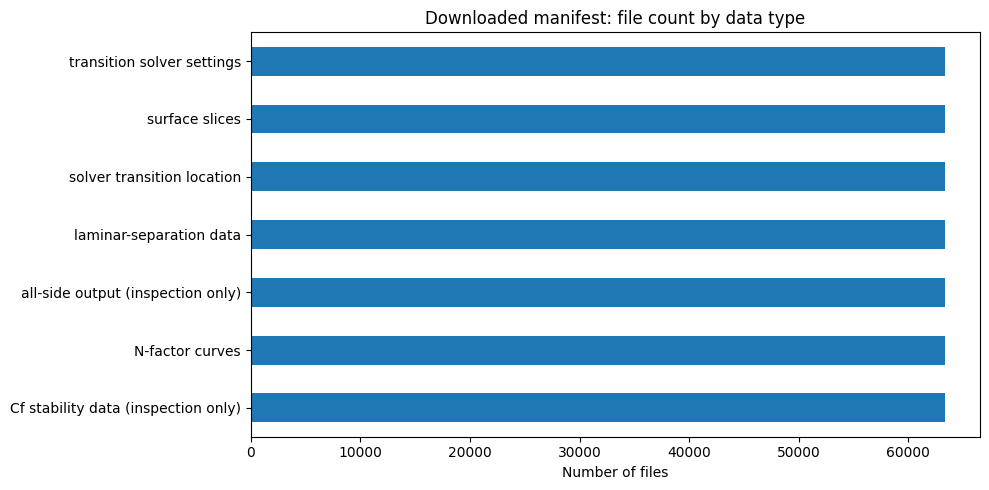

In [ ]:
import gzip
import re
import zipfile
from collections import Counter
import matplotlib.pyplot as plt

manifest = pd.read_csv(MANIFEST_PATH, compression="gzip", low_memory=False)
required_columns = {"archive", "name", "bytes", "shard"}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing expected columns: {sorted(missing_columns)}")

CASE_RE = re.compile(r"airfoil_(\d+)_G\d+_[A-Za-z0-9]+_L\d+_case_(\d+)")
def file_kind(name):
    base = Path(str(name)).name.lower()
    if base.endswith("_slices.dat"):
        return "surface slices"
    if base == "transiloc.dat":
        return "solver transition location"
    if base == "nfactor_ts.dat":
        return "N-factor curves"
    if base == "bledge_info.dat":
        return "laminar-separation data"
    if base == "nfactor_cf.dat":
        return "Cf stability data (inspection only)"
    if base == "allsideout.dat":
        return "all-side output (inspection only)"
    if base == "tscf_info.dat":
        return "transition solver settings"
    return Path(base).suffix or "other"

manifest["file_kind"] = manifest["name"].map(file_kind)
manifest["size_MB"] = pd.to_numeric(manifest["bytes"], errors="coerce") / 1e6
manifest["case_match"] = manifest["name"].map(lambda n: bool(CASE_RE.search(str(n))))

print(f"Manifest rows: {len(manifest):,}")
print(f"Unique shard files referenced: {manifest['shard'].nunique():,}")
print(f"Distinct airfoil/case identifiers found in manifest paths: "
      f"{manifest.loc[manifest.case_match, 'name'].map(lambda n: CASE_RE.search(str(n)).groups()).nunique() if manifest.case_match.any() else 0:,}")
display(manifest.head(10))

kind_summary = (manifest.groupby("file_kind", dropna=False)
                .agg(file_count=("name", "size"), total_MB=("size_MB", "sum"))
                .sort_values("file_count", ascending=False))
display(kind_summary)

# Count the analysis/convergence records inside the unchanged archive separately.
with zipfile.ZipFile(WHOLE_ARCHIVE) as whole_zip:
    whole_names = whole_zip.namelist()
analysis_count = sum(Path(n).name.endswith("_analysis.csv") for n in whole_names)
convergence_count = sum(Path(n).name.endswith("_convergence.pkl") for n in whole_names)
whole_summary = pd.DataFrame([
    {"file_kind": "analysis.csv", "file_count": analysis_count},
    {"file_kind": "convergence.pkl", "file_count": convergence_count},
])
print("Files listed in the unchanged simulation archive:")
display(whole_summary)

fig, ax = plt.subplots(figsize=(10, 5))
kind_summary["file_count"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Downloaded manifest: file count by data type")
ax.set_xlabel("Number of files")
ax.set_ylabel("")
fig.tight_layout()
if SAVE_PLOTS:
    PREP_DIR.mkdir(parents=True, exist_ok=True)
    (PREP_DIR / "visualizations").mkdir(exist_ok=True)
    fig.savefig(PREP_DIR / "visualizations" / "manifest_file_counts.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.1 Check that shard files listed in the manifest exist

This is a file-presence check. It is not a complete checksum re-verification; the downloader already checks extracted entries against their ZIP metadata.

In [ ]:
def expected_shard_path(row):
    # Expected layout: raw/<archive basename without .zip>/<shard>
    archive_stem = Path(str(row["archive"])).name[:-4]
    return RAW_DIR / "raw" / archive_stem / str(row["shard"])

unique_shards = manifest[["archive", "shard"]].drop_duplicates().copy()
unique_shards["expected_path"] = unique_shards.apply(expected_shard_path, axis=1)
unique_shards["exists"] = unique_shards["expected_path"].map(lambda p: p.is_file())
print(f"Shard files found: {unique_shards['exists'].sum():,} / {len(unique_shards):,}")
if not unique_shards["exists"].all():
    display(unique_shards.loc[~unique_shards["exists"]].head(20))
else:
    print("All shard paths referenced by the manifest exist.")

Shard files found: 47 / 47
All shard paths referenced by the manifest exist.


## 7. Run the original preprocessing script

The first run is limited to 300 sorted cases and writes to `prepared/try_300`. The source script resumes saved batches when possible. To process all cases later, set `MAX_CASES = None` in Section 3 and rerun this cell.

## 7. Run the embedded preprocessing pipeline

The trial processes the first `MAX_CASES` sorted cases and writes to `prepared/try_300`. After inspecting the report and plots, change `MAX_CASES = None` in the configuration cell to run all cases. Existing completed case batches are reused. Set `REDO_CONVERGENCE` or `REDO_NFACTOR` to `True` only when you specifically need to refresh those extracted fields.

In [ ]:
# These options are normally left False. They refresh fields in existing saved case batches.
REDO_CONVERGENCE = False
REDO_NFACTOR = False

if RUN_PREPROCESS:
    prepared_table, actual_output_dir = run_preprocessing(
        raw_dir=RAW_DIR,
        out_base_dir=PREP_BASE_DIR,
        max_cases=MAX_CASES,
        redo_convergence=REDO_CONVERGENCE,
        redo_nfactor=REDO_NFACTOR,
    )
    PREP_DIR = Path(actual_output_dir)
else:
    print("RUN_PREPROCESS=False: skipping processing and reading existing prepared outputs.")
    PREP_DIR = PREP_BASE_DIR / (f"try_{MAX_CASES}" if MAX_CASES is not None else "")

VIS_DIR = PREP_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)
CASES_PATH = PREP_DIR / "cases.csv"
print("Prepared output folder:", PREP_DIR)
if not CASES_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {CASES_PATH}. Set RUN_PREPROCESS=True or point PREP_DIR at an existing prepared run."
    )

Finding files for each case ...
Cases selected for this run: 63,373
PREPROCESSING REPORT

cases: 63,373 on 4,618 airfoils
kept for RQ1 (drag, crossover):      63,372 (100.0%)
kept for RQ2 (also transition valid): 63,078 (99.5%)
RQ1 sensitivity subset (also steady CD history): 19,162 (30.2%)

settings (fixed before the run):
  converged = total residual fell by at least 6 orders of magnitude.
  This is an EMPIRICAL screening rule, not an official UniFoil criterion: UniFoil does not
  publish its stopping rule, and 6 orders is the level at which the solver stopped in the data.
  sensitivity only: CD in the saved history changed by at most 0.1% over the last
  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)
  at least 50 slice points on each surface
  RQ1 needs: analysis, convergence, slices   RQ2 also needs: transiLoc.dat
  e^N cross-check only (reported, not removed): nfactor_ts.dat, bledge_info.dat

cases with each flag (a case can have several):
 

In [ ]:
import pandas as pd
import numpy as np

# Define 'cases' from the previously prepared table variable
cases = prepared_table

# Inspect the actual residual drop distribution and raw values
if 'residual_drop_orders' in cases:
    print("--- Summary statistics of residual_drop_orders ---")
    display(cases['residual_drop_orders'].describe())

    print("\n--- First 10 raw residual drop values ---")
    display(cases[['airfoil', 'case', 'residual_drop_orders', 'n_iter', 'cd_tail_rel_change']].head(10))

    # Count how many are NaN or null
    missing_residuals = cases['residual_drop_orders'].isna().sum()
    print(f"\nNumber of cases with missing/NaN residuals: {missing_residuals} / {len(cases)}")
else:
    print("The column 'residual_drop_orders' is missing from the cases DataFrame.")

--- Summary statistics of residual_drop_orders ---


,residual_drop_orders
count,63373.000000
mean,6.131135
std,0.085332
min,6.000005
25%,6.056108
50%,6.120750
75%,6.204576
max,6.389653



--- First 10 raw residual drop values ---


,airfoil,case,residual_drop_orders,n_iter,cd_tail_rel_change
0,1,0,6.165095,25,0.002129
1,1,1,6.141248,37,0.002068
2,1,2,6.014686,40,0.000901
3,1,3,6.215444,25,0.001266
4,1,4,6.049811,23,0.003097
5,1,5,6.032911,60,0.004619
6,1,6,6.061142,27,0.001145
7,1,7,6.141912,27,0.003099
8,1,8,6.077244,29,0.004116
9,1,9,6.199059,25,0.002104



Number of cases with missing/NaN residuals: 0 / 63373


## 8. Load and summarise the prepared case table

In [ ]:
cases = pd.read_csv(CASES_PATH, low_memory=False)
print(f"Prepared cases: {len(cases):,}")
print(f"Distinct airfoils: {cases['airfoil'].nunique():,}" if "airfoil" in cases else "No airfoil column found.")
print(f"Columns: {len(cases.columns)}")
display(cases.head(8))

# Convert keep/flag columns robustly if pandas read them as strings.
def as_bool(value):
    if pd.isna(value):
        return False
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {"true", "1", "1.0", "yes"}

for col in ["keep_rq1", "keep_rq2", "keep_rq1_strict"]:
    if col in cases:
        cases[col] = cases[col].map(as_bool)

summary_rows = []
for col, label in [("keep_rq1", "Kept for RQ1"), ("keep_rq2", "Kept for RQ2"), ("keep_rq1_strict", "Strict RQ1 subset")]:
    if col in cases:
        count = int(cases[col].sum())
        summary_rows.append({"selection": label, "kept": count, "not_kept_from_all_cases": len(cases)-count,
                             "kept_percent": 100 * count / len(cases) if len(cases) else np.nan})
display(pd.DataFrame(summary_rows))

Prepared cases: 63,373
Distinct airfoils: 4,618
Columns: 56


,airfoil,case,missing_files,Mach,AoA_stated,Re,CL_reported,CD_reported,slice_ok,n_points_upper,...,flag_transition_missing_lower,flag_transition_placeholder_lower,flag_bad_frequency_lower,flag_en_check_file_missing,flag_cd_history_unsteady,keep_rq1,keep_rq2,keep_rq1_strict,removed_from_rq1_because,removed_from_rq2_because
0,1,0,NaN,0.339795,2.724399,2890000.0,-0.000422,0.008874,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
1,1,1,NaN,0.690023,0.755782,1300000.0,-0.001137,0.086182,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
2,1,2,NaN,0.664469,1.786138,5170000.0,-0.005771,0.185051,True,148,...,False,False,False,False,False,True,True,True,NaN,NaN
3,1,3,NaN,0.190151,2.520059,1330000.0,-0.000464,0.010549,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
4,1,4,NaN,0.261451,5.818668,1040000.0,-0.001050,0.010306,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
5,1,5,NaN,0.567517,0.141196,2930000.0,-0.000025,0.010064,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
6,1,6,NaN,0.348620,3.700253,6840000.0,-0.000550,0.008503,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN
7,1,7,NaN,0.427258,4.635979,5610000.0,-0.000648,0.007992,True,148,...,False,False,False,False,True,True,True,False,NaN,NaN


,selection,kept,not_kept_from_all_cases,kept_percent
0,Kept for RQ1,63372,1,99.998422
1,Kept for RQ2,63078,295,99.534502
2,Strict RQ1 subset,19162,44211,30.236852


## 9. Visualisation: how many cases are kept?

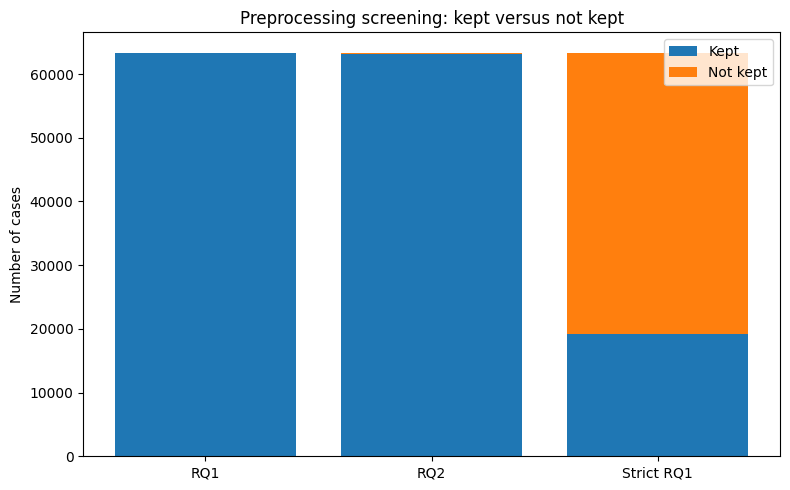

In [ ]:
selection_labels, kept_counts, excluded_counts = [], [], []
for col, label in [("keep_rq1", "RQ1"), ("keep_rq2", "RQ2"), ("keep_rq1_strict", "Strict RQ1")]:
    if col in cases:
        selection_labels.append(label)
        kept_counts.append(int(cases[col].sum()))
        excluded_counts.append(int((~cases[col]).sum()))

fig, ax = plt.subplots(figsize=(8, 5))
xpos = np.arange(len(selection_labels))
ax.bar(xpos, kept_counts, label="Kept")
ax.bar(xpos, excluded_counts, bottom=kept_counts, label="Not kept")
ax.set_xticks(xpos, selection_labels)
ax.set_ylabel("Number of cases")
ax.set_title("Preprocessing screening: kept versus not kept")
ax.legend()
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(PREP_DIR / "visualizations" / "screening_kept_vs_notkept.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Visualisation: flags and reasons for exclusion

Several flags can apply to the same case, so the bar heights below can overlap. Also, some flags are informational only; the preprocessing report defines which flags remove a case from each research-question subset.

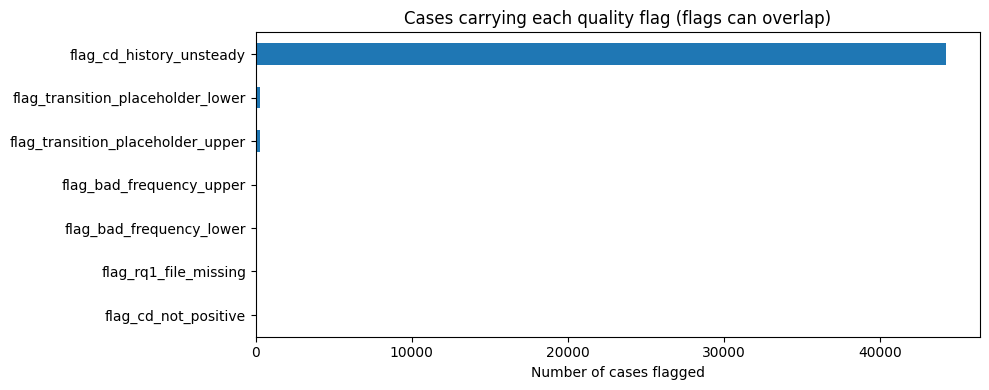

Most common removed_from_rq1_because combinations:


,cases
reason combination,
Kept,63372
"rq1_file_missing,cd_not_positive",1


Most common removed_from_rq2_because combinations:


,cases
reason combination,
Kept,63078
"transition_placeholder_upper,transition_placeholder_lower",283
bad_frequency_upper,10
bad_frequency_lower,1
"rq1_file_missing,cd_not_positive",1


In [ ]:
flag_cols = [c for c in cases.columns if c.startswith("flag_")]
if flag_cols:
    flag_counts = cases[flag_cols].apply(lambda s: s.map(as_bool).sum()).sort_values(ascending=True)
    flag_counts = flag_counts[flag_counts > 0]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.38 * len(flag_counts))))
    flag_counts.plot(kind="barh", ax=ax)
    ax.set_title("Cases carrying each quality flag (flags can overlap)")
    ax.set_xlabel("Number of cases flagged")
    ax.set_ylabel("")
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / "quality_flags.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No flag_* columns found in cases.csv.")

for col in ["removed_from_rq1_because", "removed_from_rq2_because"]:
    if col in cases:
        counts = (cases[col].fillna("").astype(str).replace("", "Kept")
                  .value_counts().head(15))
        print(f"Most common {col} combinations:")
        display(counts.rename_axis("reason combination").to_frame("cases"))

## 11. Visualisation: flight-condition distributions

These are distributions of cases in the prepared table. If this is the 300-case trial, the plots describe only that subset, not the complete UniFoil dataset.

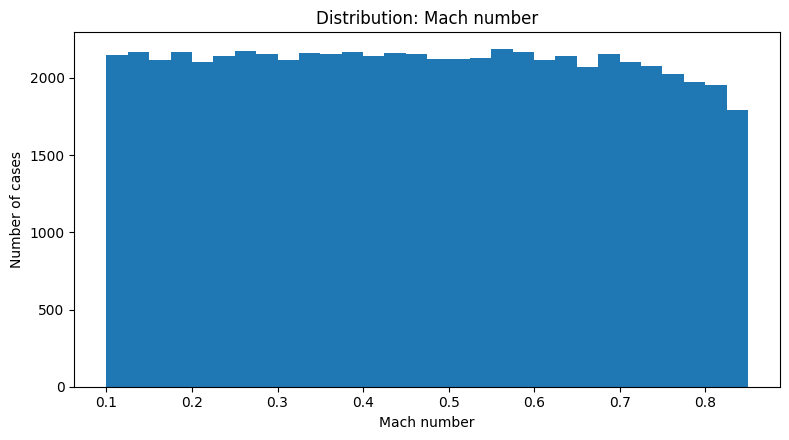

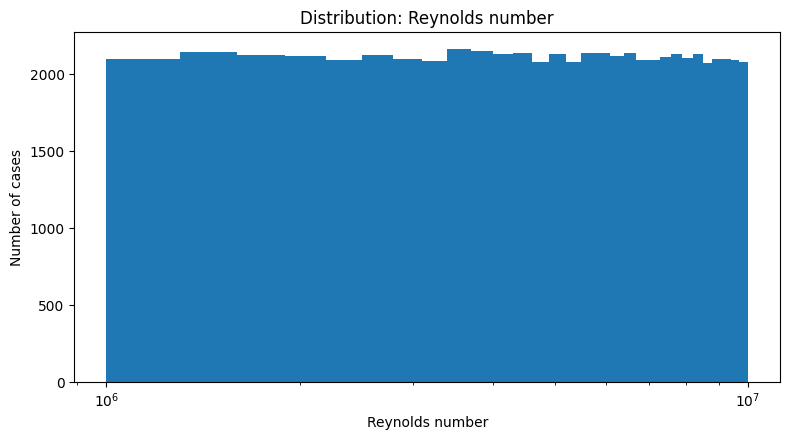

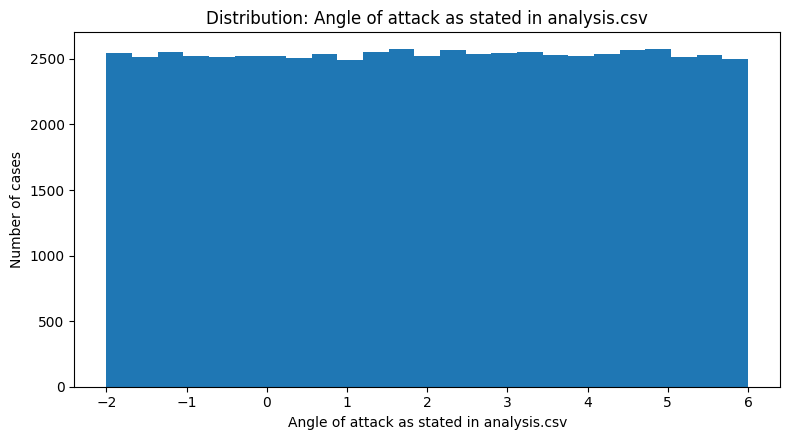

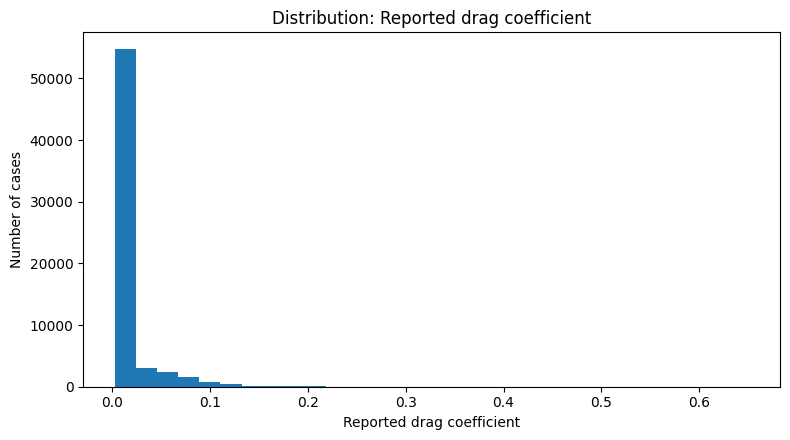

In [ ]:
hist_specs = [
    ("Mach", "Mach number", 30, False),
    ("Re", "Reynolds number", 30, True),
    ("AoA_stated", "Angle of attack as stated in analysis.csv", 25, False),
    ("CD_reported", "Reported drag coefficient", 30, False),
]
for col, label, bins, logx in hist_specs:
    if col not in cases or cases[col].dropna().empty:
        print(f"Skipping {label}: column is absent or empty.")
        continue
    values = pd.to_numeric(cases[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(values, bins=bins)
    ax.set_title(f"Distribution: {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of cases")
    if logx and (values > 0).all():
        ax.set_xscale("log")
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"hist_{col}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 12. Visualisation: Mach number versus reported drag

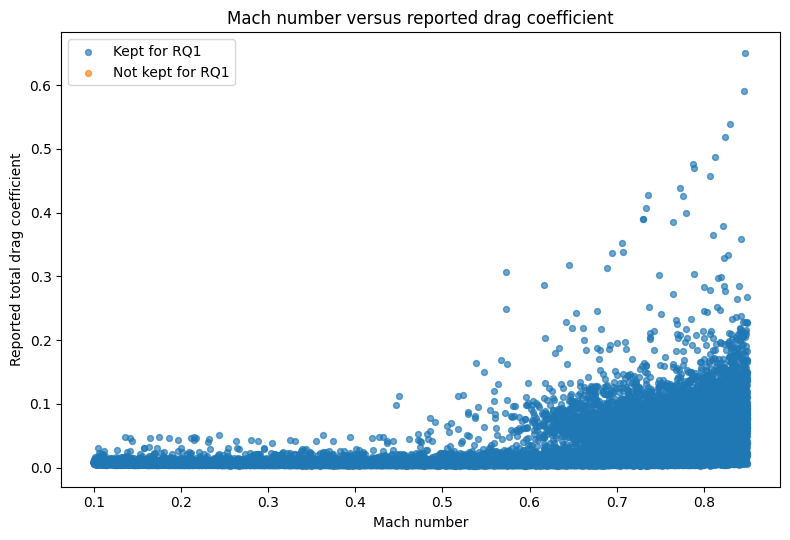

In [ ]:
if {"Mach", "CD_reported"}.issubset(cases.columns):
    plot_data = cases.copy()
    plot_data["Mach"] = pd.to_numeric(plot_data["Mach"], errors="coerce")
    plot_data["CD_reported"] = pd.to_numeric(plot_data["CD_reported"], errors="coerce")
    fig, ax = plt.subplots(figsize=(8, 5.5))
    if "keep_rq1" in plot_data:
        for keep_value, label in [(True, "Kept for RQ1"), (False, "Not kept for RQ1")]:
            g = plot_data[plot_data.keep_rq1 == keep_value].dropna(subset=["Mach", "CD_reported"])
            ax.scatter(g["Mach"], g["CD_reported"], s=18, alpha=0.65, label=label)
        ax.legend()
    else:
        ax.scatter(plot_data["Mach"], plot_data["CD_reported"], s=18, alpha=0.65)
    ax.set_xlabel("Mach number")
    ax.set_ylabel("Reported total drag coefficient")
    ax.set_title("Mach number versus reported drag coefficient")
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / "mach_vs_cd.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Mach or CD_reported not available; skipping plot.")

## 13. Visualisation: residual reduction and drag-history stability

The vertical line at 6 orders marks the empirical residual screening threshold used by this notebook. The horizontal line at 0.001 (0.1%) is used only for the `keep_rq1_strict` sensitivity subset. These lines represent code settings, not universal CFD standards.

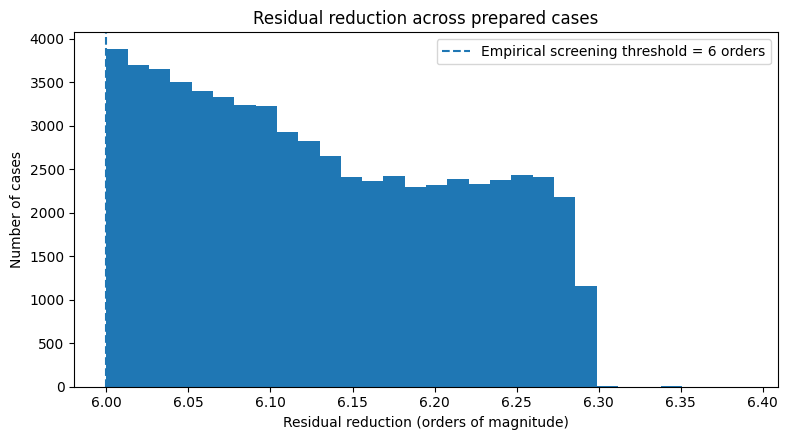

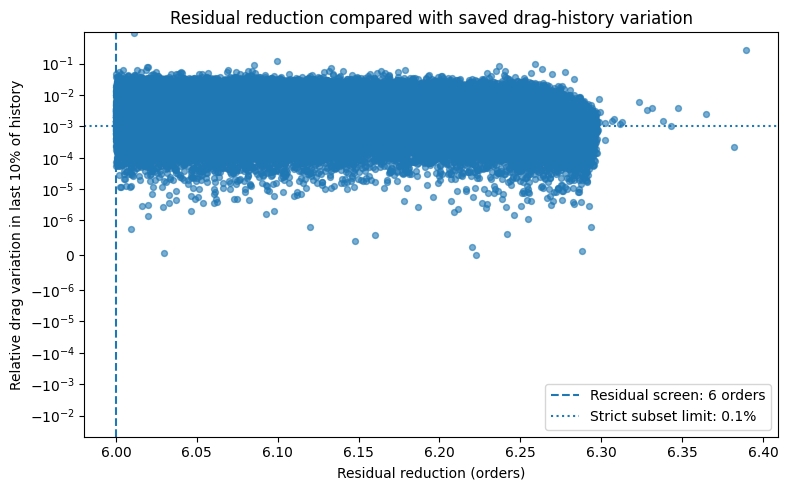

In [ ]:
if "residual_drop_orders" in cases:
    d = pd.to_numeric(cases["residual_drop_orders"], errors="coerce").dropna()
    if len(d):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.hist(d, bins=30)
        ax.axvline(6.0, linestyle="--", label="Empirical screening threshold = 6 orders")
        ax.set_xlabel("Residual reduction (orders of magnitude)")
        ax.set_ylabel("Number of cases")
        ax.set_title("Residual reduction across prepared cases")
        ax.legend()
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "residual_drop_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()

if {"residual_drop_orders", "cd_tail_rel_change"}.issubset(cases.columns):
    tmp = cases[["residual_drop_orders", "cd_tail_rel_change"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(tmp):
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.scatter(tmp["residual_drop_orders"], tmp["cd_tail_rel_change"], s=18, alpha=0.6)
        ax.axvline(6.0, linestyle="--", label="Residual screen: 6 orders")
        ax.axhline(0.001, linestyle=":", label="Strict subset limit: 0.1%")
        # Symmetric-log scale can display exact zeros as well as very small positive changes.
        ax.set_yscale("symlog", linthresh=1e-6)
        ax.set_xlabel("Residual reduction (orders)")
        ax.set_ylabel("Relative drag variation in last 10% of history")
        ax.set_title("Residual reduction compared with saved drag-history variation")
        ax.legend()
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "residual_vs_cd_stability.png", dpi=160, bbox_inches="tight")
        plt.show()

## 14. Visualisation: airfoil geometry versus drag

These plots help inspect whether basic geometry descriptors appear associated with the reported drag in the processed cases. A scatter plot is descriptive only; it does not establish causation or account for Mach, Reynolds number and angle of attack.

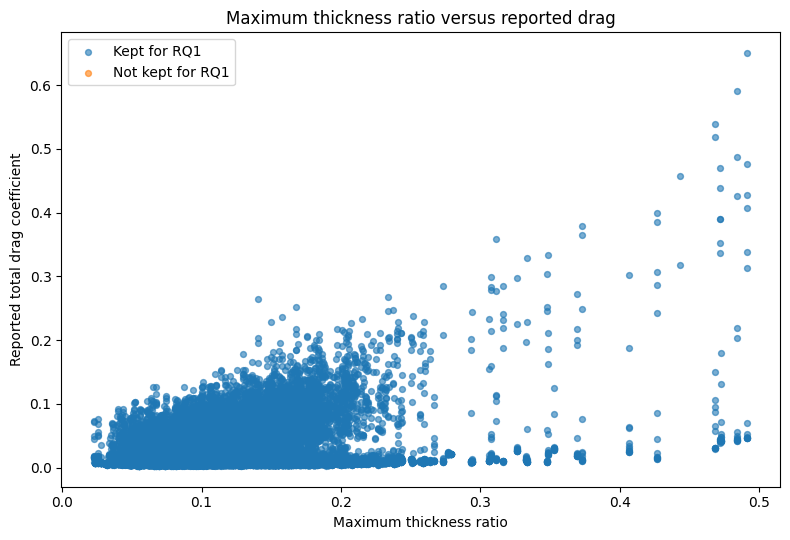

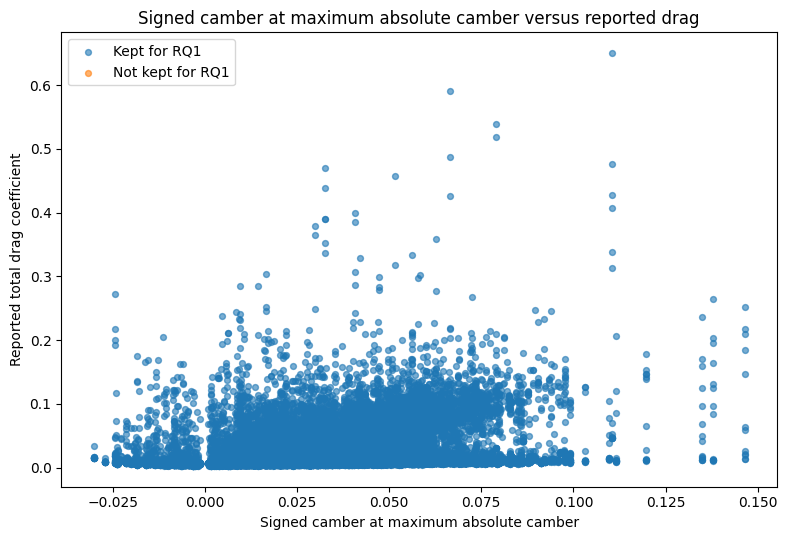

In [ ]:
for xcol, xlabel, filename in [
    ("t_max", "Maximum thickness ratio", "thickness_vs_cd.png"),
    ("camber_max", "Signed camber at maximum absolute camber", "camber_vs_cd.png"),
]:
    if xcol in cases and "CD_reported" in cases:
        tmp = cases[[xcol, "CD_reported"] + (["keep_rq1"] if "keep_rq1" in cases else [])].copy()
        tmp[xcol] = pd.to_numeric(tmp[xcol], errors="coerce")
        tmp["CD_reported"] = pd.to_numeric(tmp["CD_reported"], errors="coerce")
        tmp = tmp.dropna(subset=[xcol, "CD_reported"])
        fig, ax = plt.subplots(figsize=(8, 5.5))
        if "keep_rq1" in tmp:
            for keep_value, label in [(True, "Kept for RQ1"), (False, "Not kept for RQ1")]:
                g = tmp[tmp.keep_rq1 == keep_value]
                ax.scatter(g[xcol], g["CD_reported"], s=18, alpha=0.6, label=label)
            ax.legend()
        else:
            ax.scatter(tmp[xcol], tmp["CD_reported"], s=18, alpha=0.6)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Reported total drag coefficient")
        ax.set_title(f"{xlabel} versus reported drag")
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / filename, dpi=160, bbox_inches="tight")
        plt.show()

## 15. Inspect one actual prepared case

The following cell selects the first case marked usable for RQ1 by default. You can replace `SELECT_AIRFOIL` and `SELECT_CASE` with the identifiers you want to inspect. It reads only the selected case's rows from the Parquet files when the installed Parquet engine supports filters.

In [ ]:
# Change these to specific IDs, or leave both as None to auto-select a kept case.
SELECT_AIRFOIL = None
SELECT_CASE = None

if cases.empty:
    raise ValueError("cases.csv contains no cases to inspect. Check the preprocessing output/report.")

if SELECT_AIRFOIL is None or SELECT_CASE is None:
    if "keep_rq1" in cases and cases.keep_rq1.any():
        selected = cases.loc[cases.keep_rq1].iloc[0]
    else:
        selected = cases.iloc[0]
    SELECT_AIRFOIL = int(selected["airfoil"])
    SELECT_CASE = int(selected["case"])
else:
    matched = cases[(cases.airfoil == int(SELECT_AIRFOIL)) & (cases.case == int(SELECT_CASE))]
    if matched.empty:
        raise KeyError(f"Case airfoil={SELECT_AIRFOIL}, case={SELECT_CASE} is not in cases.csv")
    selected = matched.iloc[0]

print(f"Selected airfoil={SELECT_AIRFOIL}, case={SELECT_CASE}")
show_cols = [c for c in ["Mach", "Re", "AoA_stated", "CL_reported", "CD_reported", "t_max", "x_t_max",
                         "camber_max", "x_camber_max", "residual_drop_orders", "keep_rq1", "keep_rq2", "keep_rq1_strict"]
             if c in selected.index]
display(pd.DataFrame({"value": selected[show_cols]}))

SURFACE_DIR = PREP_DIR / "surfaces"
SURFACE_COLUMNS = ["airfoil", "case", "surface", "i", "x", "y", "cp", "cf", "cfx"]
def load_selected_surface(airfoil_id, case_id):
    chunks = []
    paths = sorted(SURFACE_DIR.glob("*.parquet"))
    for path in paths:
        try:
            part = pd.read_parquet(
                path, columns=SURFACE_COLUMNS,
                filters=[("airfoil", "==", int(airfoil_id)), ("case", "==", int(case_id))]
            )
        except (TypeError, ValueError, KeyError):
            part = pd.read_parquet(path, columns=SURFACE_COLUMNS)
            part = part[(part.airfoil == int(airfoil_id)) & (part.case == int(case_id))]
        if not part.empty:
            chunks.append(part)
    if not chunks:
        return pd.DataFrame(columns=SURFACE_COLUMNS)
    return pd.concat(chunks, ignore_index=True).sort_values(["surface", "i"])

surface_case = load_selected_surface(SELECT_AIRFOIL, SELECT_CASE)
if surface_case.empty:
    print("No surface rows found for this case. Check the case IDs and prepared/surfaces files.")
else:
    display(surface_case.groupby("surface").agg(points=("x", "size"), x_min=("x", "min"), x_max=("x", "max")))

Selected airfoil=1, case=0


,value
Mach,0.339795
Re,2890000.0
AoA_stated,2.724399
CL_reported,-0.000422
CD_reported,0.008874
t_max,0.293177
x_t_max,0.36
camber_max,0.016185
x_camber_max,0.545
residual_drop_orders,6.165095


,points,x_min,x_max
surface,,,
lower,158,-0.000002,0.999988
upper,148,-0.000002,0.999988


## 16. Visualisation: geometry, pressure coefficient and skin friction

The figures below are generated from the selected case's prepared surface data. The conventional pressure-coefficient plot has an inverted vertical axis so more negative pressure coefficients appear higher on the graph.

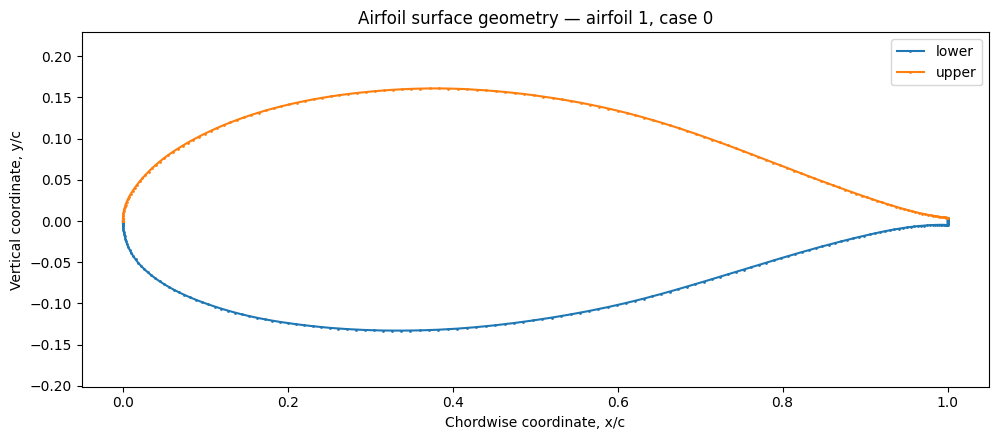

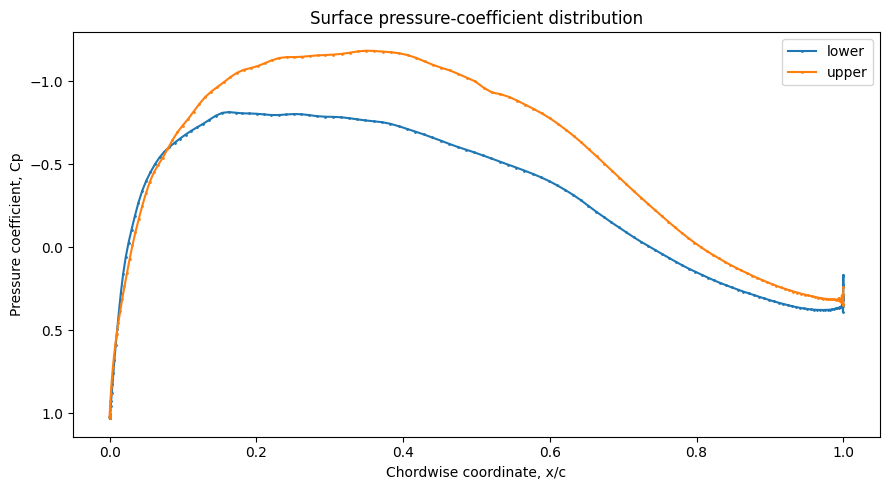

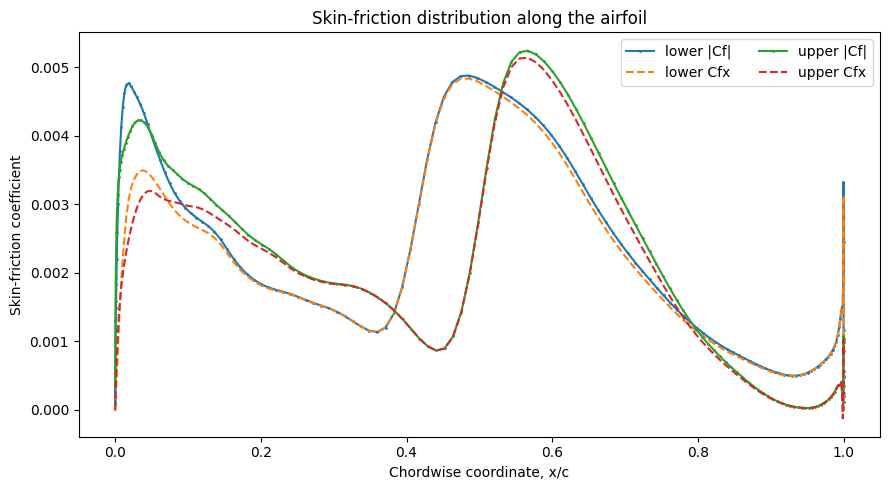

In [ ]:
if not surface_case.empty:
    # Airfoil geometry
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["y"], marker=".", markersize=2, label=side)
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Vertical coordinate, y/c")
    ax.set_title(f"Airfoil surface geometry — airfoil {SELECT_AIRFOIL}, case {SELECT_CASE}")
    ax.axis("equal")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_geometry.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Pressure coefficient
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["cp"], marker=".", markersize=2, label=side)
    ax.invert_yaxis()
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Pressure coefficient, Cp")
    ax.set_title("Surface pressure-coefficient distribution")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_cp.png", dpi=160, bbox_inches="tight")
    plt.show()

    # Skin friction magnitude and streamwise component
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in surface_case.groupby("surface"):
        ax.plot(g["x"], g["cf"], marker=".", markersize=2, label=f"{side} |Cf|")
        ax.plot(g["x"], g["cfx"], linestyle="--", label=f"{side} Cfx")
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("Skin-friction coefficient")
    ax.set_title("Skin-friction distribution along the airfoil")
    ax.legend(ncol=2)
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_cf.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Plots skipped because the selected case has no prepared surface data.")

## 17. Visualisation: N-factor envelope (when available)

The embedded preprocessing code saves usable N-factor envelope data when it can build it from the individual wave-frequency zones. Cases with no usable N-factor data can still have a valid solver-reported transition location; missing cross-check data should not be misrepresented as a threshold crossing.

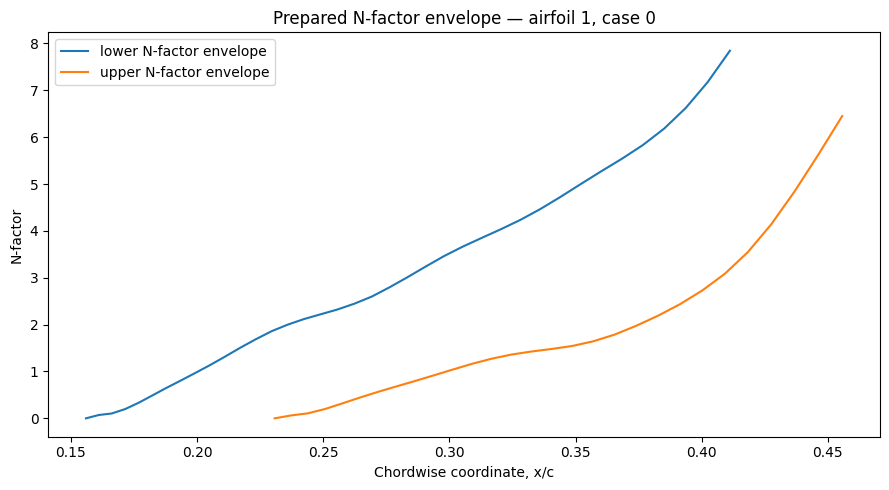

In [ ]:
TRANSITION_DIR = PREP_DIR / "transition_inputs"
NFACTOR_COLUMNS = ["airfoil", "case", "surface", "x", "N"]
def load_selected_nfactor(airfoil_id, case_id):
    chunks = []
    for path in sorted(TRANSITION_DIR.glob("*.parquet")):
        try:
            part = pd.read_parquet(path, columns=NFACTOR_COLUMNS,
                                   filters=[("airfoil", "==", int(airfoil_id)), ("case", "==", int(case_id))])
        except (TypeError, ValueError, KeyError):
            part = pd.read_parquet(path, columns=NFACTOR_COLUMNS)
            part = part[(part.airfoil == int(airfoil_id)) & (part.case == int(case_id))]
        if not part.empty:
            chunks.append(part)
    if not chunks:
        return pd.DataFrame(columns=NFACTOR_COLUMNS)
    return pd.concat(chunks, ignore_index=True).sort_values(["surface", "x"])

nf_case = load_selected_nfactor(SELECT_AIRFOIL, SELECT_CASE)
if nf_case.empty:
    print("No usable N-factor envelope was saved for this selected case.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    for side, g in nf_case.groupby("surface"):
        ax.plot(g["x"], g["N"], label=f"{side} N-factor envelope")
    ax.set_xlabel("Chordwise coordinate, x/c")
    ax.set_ylabel("N-factor")
    ax.set_title(f"Prepared N-factor envelope — airfoil {SELECT_AIRFOIL}, case {SELECT_CASE}")
    ax.legend()
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PREP_DIR / "visualizations" / f"case_{SELECT_AIRFOIL}_{SELECT_CASE}_nfactor.png", dpi=160, bbox_inches="tight")
    plt.show()

## 18. Inspect the preprocessing report and removal-by-band table

PREPROCESSING REPORT

cases: 63,373 on 4,618 airfoils
kept for RQ1 (drag, crossover):      63,372 (100.0%)
kept for RQ2 (also transition valid): 63,078 (99.5%)
RQ1 sensitivity subset (also steady CD history): 19,162 (30.2%)

settings (fixed before the run):
  converged = total residual fell by at least 6 orders of magnitude.
  This is an EMPIRICAL screening rule, not an official UniFoil criterion: UniFoil does not
  publish its stopping rule, and 6 orders is the level at which the solver stopped in the data.
  sensitivity only: CD in the saved history changed by at most 0.1% over the last
  10 % of iterations (our choice; used only for keep_rq1_strict, never to remove cases)
  at least 50 slice points on each surface
  RQ1 needs: analysis, convergence, slices   RQ2 also needs: transiLoc.dat
  e^N cross-check only (reported, not removed): nfactor_ts.dat, bledge_info.dat

cases with each flag (a case can have several):
  rq1_file_missing                          1   (removes from RQ1 and

,cases,removed_rq1,removed_rq2,kept_rq1_strict
"Mach (0.099, 0.3]",17176,0.0,0.004774,0.045238
"Mach (0.3, 0.5]",17184,0.0,0.005587,0.398219
"Mach (0.5, 0.7]",17085,0.0,0.003395,0.457536
"Mach (0.7, 0.86]",11927,0.0,0.004863,0.312317
"Re (999999.999, 3250000.0]",15911,0.0,0.007291,0.218402
"Re (3250000.0, 5500000.0]",15908,0.0,0.005029,0.382072
"Re (5500000.0, 7750000.0]",15918,0.0,0.003581,0.329815
"Re (7750000.0, 10100000.0]",15635,0.0,0.002622,0.278798
"AoA_stated (-2.0109999999999997, 0.0]",15809,0.0,0.004871,0.311721
"AoA_stated (0.0, 2.0]",15822,0.0,0.004045,0.303312


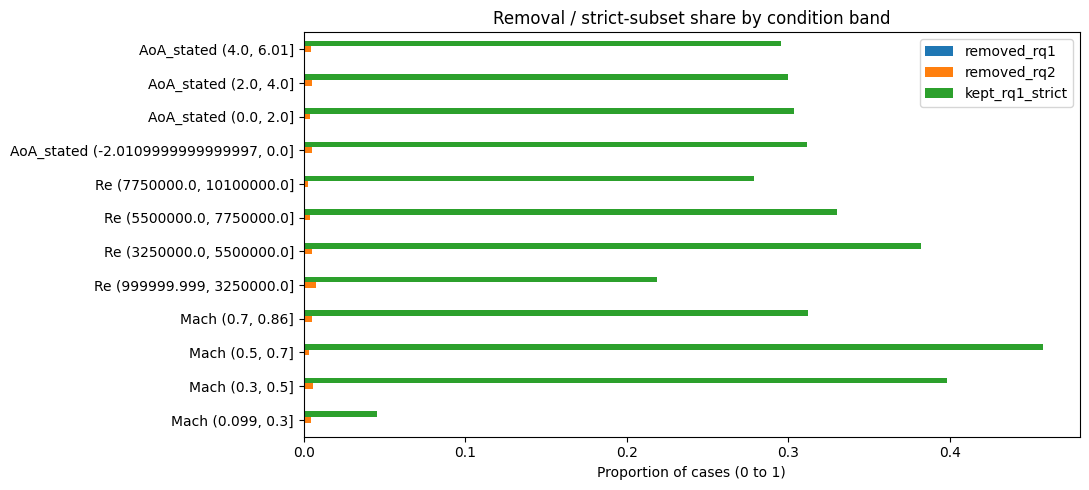

In [ ]:
REPORT_PATH = PREP_DIR / "preprocessing_report.txt"
if REPORT_PATH.is_file():
    print(REPORT_PATH.read_text(errors="replace"))
else:
    print("No preprocessing_report.txt found.")

BAND_PATH = PREP_DIR / "removal_by_band.csv"
if BAND_PATH.is_file():
    bands = pd.read_csv(BAND_PATH, index_col=0)
    display(bands)
    cols = [c for c in ["removed_rq1", "removed_rq2", "kept_rq1_strict"] if c in bands]
    if cols:
        fig, ax = plt.subplots(figsize=(11, max(5, 0.32 * len(bands))))
        bands[cols].plot(kind="barh", ax=ax)
        ax.set_xlabel("Proportion of cases (0 to 1)")
        ax.set_title("Removal / strict-subset share by condition band")
        ax.legend(loc="best")
        fig.tight_layout()
        if SAVE_PLOTS:
            fig.savefig(PREP_DIR / "visualizations" / "removal_by_band.png", dpi=160, bbox_inches="tight")
        plt.show()
else:
    print("No removal_by_band.csv found. It is generated when usable flight-condition bands are available.")

## 19. Export and final checklist

If `SAVE_PLOTS=True`, figures are saved under `PREP_DIR/visualizations/`. The notebook does not export or modify raw files.

In [ ]:
print("Prepared folder:", PREP_DIR.resolve())
print("Cases table:", CASES_PATH, "exists =", CASES_PATH.is_file())
print("Surface Parquet files:", len(list((PREP_DIR / "surfaces").glob("*.parquet"))))
print("N-factor Parquet files:", len(list((PREP_DIR / "transition_inputs").glob("*.parquet"))))
print("Saved visualisations:", len(list((PREP_DIR / "visualizations").glob("*.png"))) if (PREP_DIR / "visualizations").exists() else 0)

print("\nBefore a full run, check:")
print("  1. The trial completed and cases.csv was created.")
print("  2. The preprocessing report's excluded-case counts and reason flags are plausible.")
print("  3. Geometry and surface plots look reasonable for several different cases.")
print("  4. The six-order residual threshold is described in your methodology as empirical, not official.")
print("  5. You are ready for the additional time and storage needed for all cases before setting MAX_CASES=None.")

Prepared folder: /content/drive/MyDrive/unifoil_project/prepared
Cases table: /content/drive/MyDrive/unifoil_project/prepared/cases.csv exists = True
Surface Parquet files: 32
N-factor Parquet files: 32
Saved visualisations: 17

Before a full run, check:
  1. The trial completed and cases.csv was created.
  2. The preprocessing report's excluded-case counts and reason flags are plausible.
  3. Geometry and surface plots look reasonable for several different cases.
  4. The six-order residual threshold is described in your methodology as empirical, not official.
  5. You are ready for the additional time and storage needed for all cases before setting MAX_CASES=None.


## Quick interpretation guide

- **Mach vs CD:** describes how reported total drag varies across the processed cases; it is not the crossover curve because pressure and friction drag have not yet been decomposed here.
- **Residual-drop histogram:** shows how cases compare with this notebook's empirical 6-order screen.
- **`keep_rq1` / `keep_rq2`:** different eligibility criteria for drag/crossover and transition-related analyses.
- **Geometry vs CD:** useful for exploratory patterns, but other conditions also affect drag; do not infer cause from a simple scatter plot.
- **Geometry / Cp / Cf plots:** let you visually inspect the reconstructed surface coordinates and coefficients for one case.
- **N-factor plot:** appears only when usable envelope data were saved for the selected case.
- **Removal-by-band plot:** helps look for obvious condition-dependent removal patterns. Similar rates do not prove that all selection bias is absent.

The actual drag decomposition, crossover-Mach identification, and the RQ2 link test are downstream research stages described by the comments in your preprocessing script; this notebook does not pretend to calculate those final results.